# Planning use case — experiments

Experiments for the planning use case of *Estimating the Installed Capacity of
Aggregated Thermostatically Controlled Loads from Net Load and Temperature*.
Each step calls one function of `scripts/planning.py`. Step reports, expectations
and deviations are in `RESULTS_LOG.md`; figures go to `figures/planning/`.

Every step pickles its results under `results/planning/`. With its `REBUILD_*`
flag at `False`, a step reloads them instead of recomputing.

In [1]:
import os, sys
_root = os.getcwd()
while not os.path.isdir(os.path.join(_root, 'paper')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
for _p in ('scripts', 'src'):
    if os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))

import pandas as pd
import planning as PL
pd.set_option('display.width', 200)

# control flags: True recomputes the step and overwrites its pickles
REBUILD_STEP0 = False
REBUILD_STEP1 = False   # True rescans ~1700 raw Swiss meter files (about 2 min)
REBUILD_SPLITS = False  # the split pool of Steps 2-5 (non-HP halves)
REBUILD_STEP2 = False
print('repo root:', _root)

repo root: C:\Users\VENANCIA\OneDrive - VITO\Desktop\hp-sensitivity-paper


## Step 0 — Reproduce the baseline

Rebuilds the published 20-split Kloten design (seed 0, 1260 aggregates, target
aggregates drawn from all 1307 households without an HP) and checks every draft
number against its tolerance.

In [2]:
checks, step0 = PL.reproduce_baseline(rebuild=REBUILD_STEP0)
print('rebuilt design identical to the paper cache:', step0['same_as_paper_cache'])
checks

full Kloten pilot (50 HPs): b 0.0288 m 0.01795 T_h 16.55 (module constants: {'base': 0.0288, 'slope': 0.01795, 't_thr': 16.55})
 e_r1  head       fe_r1       fa_r1  r1_days            agg  n     cap   cap_e    err  oracle   whole    plan  m_own    T_h  net_r2   e_all  e_below  flex  flex_b  flex_true_cap
0.912 1.050 3657.818115 3822.899902      248  Affoltern, CH 21 109.325 111.982  2.431   5.902  -3.319   3.943  0.017 16.723   0.949 -15.377   -8.843 0.872   0.957          0.852
0.886 1.044 1558.791992 1685.050049      245 Einsiedeln, CH  6  50.589  47.771 -5.570   5.197 -19.693  -6.036  0.016 14.008   0.954 -18.145  -11.370 0.838   0.925          0.888
0.922 1.009 5422.161133 5829.335938      233    Hamelin, DE 37 238.514 216.964 -9.035   3.255 -25.572 -25.982  0.016 13.871   0.841 -15.021   -7.834 0.845   0.930          0.929
wrote tab_real.tex
rebuilt design identical to the paper cache: True


,quantity,draft,reproduced,tol,ok
0,wape_i,19.3000,19.345896,0.5000,True
1,wape_i_le15,57.5000,57.466024,0.5000,True
2,wape_i_15_35,26.3000,26.288055,0.5000,True
3,wape_i_35_65,17.0000,17.042102,0.5000,True
4,wape_i_gt65,14.2000,14.220717,0.5000,True
5,wape_ii,14.5000,14.513574,0.5000,True
6,wape_iv,21.1000,21.075564,0.5000,True
7,median_over_pct,16.0000,15.901290,0.5000,True
8,mae_kw,17.0000,16.757828,0.5000,True
9,mean_hp_kw,6.3000,6.297227,0.0500,True


## Step 1 — Inventory of the data

1.1 completeness per winter (raw Swiss files; HEAPO from the kept daily coverage),
1.2 PV flags, 1.3 blocking periods of the 50 Kloten HPs, 1.4 nameplate ratings,
1.5 household structure of the real aggregates.

In [3]:
inv = PL.step1_inventory(rebuild=REBUILD_STEP1)
PL.years_table(inv['years'])

source       heapo     swiss    
role          free  hp  free  hp
W2019/20         0   0     0   0
W2020/21         0   0     0   0
W2021/22         0   4     0   0
W2022/23         1  22     0   0
W2023/24         0   0  1216  22
W2024/25         0   0     0   0
cal2023 heat     0  22  1226  23
cal2024 heat     0   0  1177  22

In [4]:
inv['pv'].groupby(['source', 'role']).agg(n=('pv_flag', 'size'), pv=('pv_flag', 'sum'))

n  pv
source role          
heapo  free     1   1
       hp      26  25
swiss  free  1306  15
       hp      24   1

cold days 19 | cold weekdays 13


figures\planning\fig_step1_blocking
HPs off 11:00-12:00 on >= 80 % of cold weekdays: 34 of 50


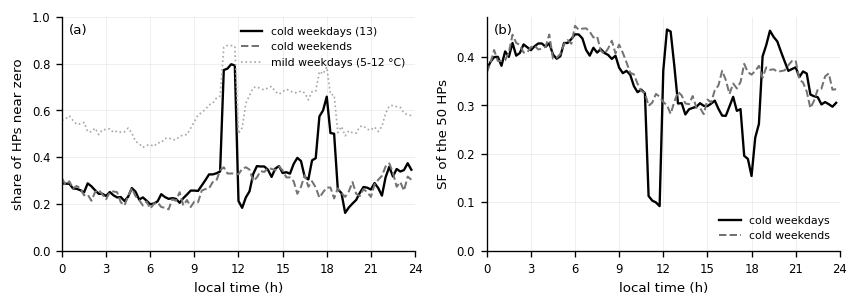

In [5]:
B = inv['blocking']
print('cold days', B['n_cold'], '| cold weekdays', B['n_cold_wkd'])
print(PL.fig_blocking(B))
blocked_11 = [h for h, r in inv['windows'].items() if any(a <= 44 and b >= 48 for a, b in r)]
print('HPs off 11:00-12:00 on >= 80 % of cold weekdays:', len(blocked_11), 'of', len(inv['windows']))

In [6]:
display(inv['nameplate']); inv['real']

,station,n_hp,heapo,with_protocol,HeatingCapacity,ElectricPower,HeatingPower
0,KLO,50,26,1,1,0,0
1,Hg,21,21,6,4,1,1
2,MqO,6,6,3,2,0,0


,aggregate,n_hp_households,hp_series,other_load_series,non_hp_households,non_hp_without_eheat,resolution
0,Hg,21,21,21,0,0,15 min
1,MqO,6,6,6,0,0,15 min
2,Hamelin (WPuQ),37,37,37,0,0,0 days 00:15:00


## Step 2 — Increment model on the pilot side

c(N, k0, k1): rise of the annual 15-min peak per kW of added HP capacity, when
k1 - k0 households without an HP are replaced by HP households. Pilot side only:
pilot HPs (A) and pilot-side households without an HP (C).

In [7]:
splits = PL.plan_splits(rebuild=REBUILD_SPLITS)
inc = PL.increment_model(draws=100, rebuild=REBUILD_STEP2)
G2 = inc['rows']
print('P_unit (mean pilot HP capacity, kW) over splits:')
print(inc['units'].P_unit.describe().round(2).to_string())
PL.split_summary(G2, ['N', 'k0', 'k1'], 'c_max').round(3)

P_unit (mean pilot HP capacity, kW) over splits:
count    20.00
mean      6.35
std       0.53
min       5.50
25%       5.90
50%       6.46
75%       6.75
max       7.29


med    q25    q75     lo     hi
N  k0 k1                                   
30 0  5   0.674  0.645  0.722  0.547  0.853
      10  0.675  0.651  0.729  0.579  0.828
      15  0.668  0.648  0.731  0.617  0.827
      20  0.675  0.642  0.724  0.588  0.819
      25  0.674  0.637  0.719  0.580  0.827
   5  10  0.664  0.649  0.737  0.630  0.797
      15  0.686  0.640  0.726  0.622  0.820
      20  0.675  0.624  0.727  0.596  0.813
      25  0.662  0.628  0.725  0.579  0.818
   10 15  0.657  0.620  0.727  0.592  0.813
      20  0.672  0.620  0.721  0.584  0.822
      25  0.668  0.622  0.716  0.559  0.814
   15 20  0.654  0.605  0.710  0.524  0.803
      25  0.656  0.602  0.708  0.528  0.814
   20 25  0.635  0.614  0.697  0.534  0.820
40 0  5   0.640  0.629  0.697  0.548  0.837
      10  0.662  0.634  0.712  0.570  0.825
      15  0.663  0.637  0.714  0.587  0.826
      20  0.662  0.632  0.711  0.573  0.825
      25  0.660  0.621  0.707  0.565  0.826
   5  10  0.654  0.626  0.711  0.581  0.791
      15  0.663  0.628  0.717  0.603  0.826
      20  0.662  0.625  0.729  0.569  0.829
      25  0.662  0.616  0.722  0.563  0.820
   10 15  0.655  0.625  0.708  0.589  0.832
      20  0.662  0.615  0.722  0.582  0.838
      25  0.653  0.609  0.710  0.543  0.824
   15 20  0.655  0.616  0.704  0.514  0.763
      25  0.661  0.594  0.718  0.501  0.810
   20 25  0.654  0.596  0.722  0.502  0.798
50 0  5   0.631  0.595  0.691  0.529  0.775
      10  0.651  0.623  0.689  0.558  0.781
      15  0.649  0.617  0.703  0.573  0.790
      20  0.653  0.616  0.713  0.566  0.809
      25  0.652  0.615  0.705  0.558  0.814
   5  10  0.636  0.621  0.699  0.574  0.762
      15  0.664  0.618  0.704  0.587  0.795
      20  0.665  0.621  0.709  0.564  0.819
      25  0.650  0.618  0.712  0.558  0.825
   10 15  0.669  0.606  0.718  0.564  0.810
      20  0.655  0.606  0.717  0.570  0.849
      25  0.648  0.615  0.714  0.535  0.851
   15 20  0.649  0.616  0.689  0.518  0.803
      25  0.649  0.607  0.726  0.523  0.832
   20 25  0.657  0.582  0.720  0.524  0.819

figures\planning\fig_step2_increment


med       q25       q75   cell_lo   cell_hi
variant N                                                   
max     30  0.671823  0.634814  0.716398  0.634949  0.685993
        40  0.658637  0.620643  0.709240  0.640410  0.662721
        50  0.651967  0.615222  0.706792  0.631378  0.668710
p999    30  0.595926  0.576271  0.627925  0.570523  0.604185
        40  0.587984  0.563888  0.618388  0.559248  0.597856
        50  0.580079  0.557010  0.613888  0.538592  0.594857
cold5   30  0.681997  0.652502  0.728724  0.639512  0.712833
        40  0.678286  0.648468  0.731442  0.654649  0.699356
        50  0.672507  0.646110  0.726889  0.659408  0.692863
on_max  30  0.493603  0.474393  0.511484  0.448665  0.512435
        40  0.488893  0.469164  0.511395  0.435309  0.506908
        50  0.485265  0.464900  0.505488  0.419580  0.501469
hp_max  30  0.605465  0.581713  0.627590  0.541427  0.841609
        40  0.605465  0.581713  0.627590  0.541427  0.841609
        50  0.605465  0.581713  0.627590  0.541427  0.841609

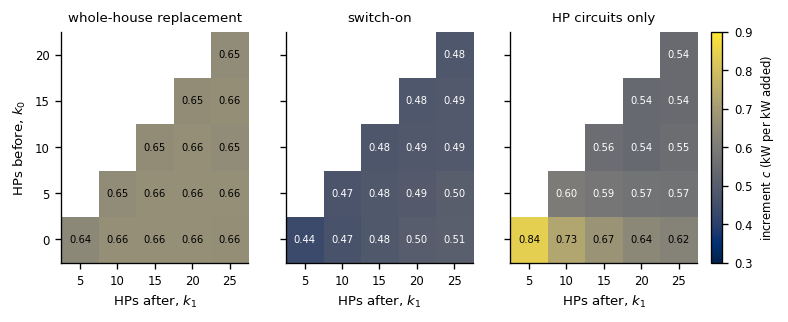

In [8]:
print(PL.fig_increment(G2))
PL.step2_tables(G2)